### Análise Exploratória de Dados (EDA) - Superconductivity Dataset 

Dataset disponível em: 

Este trabalho tem como objetivo analisar o dataset e investigar a possibilidade de prever suas temperaturas criticas utilizando as técnicas de aprendizado de maquinas implementadas na biblioteca desenvolvida na Parte I pelo grupo. 

O dataset escolhido trata de um problema de regressão supervisionada, onde buscamos prever uma variável numérica contínua (critical_temp), usando as características fisico-quimicas dos materiais, disponível no dataset. 

Nessa etapa, precisamos explorar a estrutura e características do conjunto de dados; Identificar os tipos das variaveis e inconsistencias; verificar dados ausentes, duplicados ou inválidos; Analisar outliers; analisar relações entre os preditores e a temperatura crítica; identificar necessidade de limpeza e pré-processamento necessário. 

## NOTAS/A FAZER/BRAINSTORM

Daqui sai a base de dados para aplicar a biblioteca de fato. Preciso, daqui, criar um novo df, preservando o antigo e criando um novo parametrizado com o que precisamos e da forma com que precisamos. 

In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path #buscar caminhos nos asservos do mac de forma facilitada

pd.set_option('display.max_columns', 15) #limite de colunas exibidas para não poluir a tela
pd.set_option('display.precision', 4) #conf de casas decimais exibidas

df_original = pd.read_csv("../../../data/raw/superconductivity_train.csv")
df = df_original.copy()

display(df.head())

,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,...,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence,critical_temp
0,4,88.9445,57.8627,66.3616,36.1166,1.1818,1.0624,...,1.3689,1.0662,1,1.0857,0.4330,0.4371,29.0
1,5,92.7292,58.5184,73.1328,36.3966,1.4493,1.0578,...,1.5571,1.0472,2,1.1286,0.6325,0.4686,26.0
2,4,88.9445,57.8852,66.3616,36.1225,1.1818,0.9760,...,1.3689,1.0292,1,1.1143,0.4330,0.4447,19.0
3,4,88.9445,57.8740,66.3616,36.1196,1.1818,1.0223,...,1.3689,1.0488,1,1.1000,0.4330,0.4410,22.0
4,4,88.9445,57.8401,66.3616,36.1107,1.1818,1.1292,...,1.3689,1.0961,1,1.0571,0.4330,0.4288,23.0


In [62]:
print("Número de observações:", df.shape[0])
print("Número de colunas:", df.shape[1])

print("\nNomes das colunas:")
print(df.columns.tolist())

Número de observações: 21263
Número de colunas: 82

Nomes das colunas:
['number_of_elements', 'mean_atomic_mass', 'wtd_mean_atomic_mass', 'gmean_atomic_mass', 'wtd_gmean_atomic_mass', 'entropy_atomic_mass', 'wtd_entropy_atomic_mass', 'range_atomic_mass', 'wtd_range_atomic_mass', 'std_atomic_mass', 'wtd_std_atomic_mass', 'mean_fie', 'wtd_mean_fie', 'gmean_fie', 'wtd_gmean_fie', 'entropy_fie', 'wtd_entropy_fie', 'range_fie', 'wtd_range_fie', 'std_fie', 'wtd_std_fie', 'mean_atomic_radius', 'wtd_mean_atomic_radius', 'gmean_atomic_radius', 'wtd_gmean_atomic_radius', 'entropy_atomic_radius', 'wtd_entropy_atomic_radius', 'range_atomic_radius', 'wtd_range_atomic_radius', 'std_atomic_radius', 'wtd_std_atomic_radius', 'mean_Density', 'wtd_mean_Density', 'gmean_Density', 'wtd_gmean_Density', 'entropy_Density', 'wtd_entropy_Density', 'range_Density', 'wtd_range_Density', 'std_Density', 'wtd_std_Density', 'mean_ElectronAffinity', 'wtd_mean_ElectronAffinity', 'gmean_ElectronAffinity', 'wtd_gmean_Ele

In [63]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21263 entries, 0 to 21262
Data columns (total 82 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   number_of_elements               21263 non-null  int64  
 1   mean_atomic_mass                 21263 non-null  float64
 2   wtd_mean_atomic_mass             21263 non-null  float64
 3   gmean_atomic_mass                21263 non-null  float64
 4   wtd_gmean_atomic_mass            21263 non-null  float64
 5   entropy_atomic_mass              21263 non-null  float64
 6   wtd_entropy_atomic_mass          21263 non-null  float64
 7   range_atomic_mass                21263 non-null  float64
 8   wtd_range_atomic_mass            21263 non-null  float64
 9   std_atomic_mass                  21263 non-null  float64
 10  wtd_std_atomic_mass              21263 non-null  float64
 11  mean_fie                         21263 non-null  float64
 12  wtd_mean_fie      

In [64]:
print("\nQuantidade de colunas por tipo:")
print(df.dtypes.value_counts())
print("\nColunas que não são numéricas:")
colunas_nao_numericas = df.select_dtypes(exclude="number").columns.tolist()
print(colunas_nao_numericas)
#Identifica e conta os tipos de dados presentes no df


Quantidade de colunas por tipo:
float64    79
int64       3
Name: count, dtype: int64

Colunas que não são numéricas:
[]


In [65]:
print("Quantidade de dados ausentes:")
print(df.isnull().sum().sum())

print("Quantidade de valores infinitos:")
print(np.isinf(df.to_numpy()).sum())
#Identifica e conta dados ausentes ou inválidos no df e valores infinitos 

Quantidade de dados ausentes:
0
Quantidade de valores infinitos:
0


In [66]:
df.duplicated().sum()

#Verifica se há duplicatas completas no df, olhando valores iguais para todas as variáveis. 

np.int64(66)

In [67]:
df = df.drop_duplicates()
#Remove as linhas/dados duplicados encontrados no df, mantendo apenas a primeira ocorrência de cada linha/dado duplicado.
print("Duplicatas após remoção: ", df.duplicated().sum())

Duplicatas após remoção:  0


In [68]:
#Analise Inicial da variável alvo: critical_temp
print("Tipo:", df["critical_temp"].dtype)
display(df["critical_temp"].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])) #resumo estatístivo da variável
print("Temperaturas negativas:", (df["critical_temp"] < 0).sum())
print("Temperaturas iguais a zero:", (df["critical_temp"] == 0).sum())

Tipo: float64


count    21197.0000
mean        34.4945
std         34.2765
min          0.0002
1%           0.1149
5%           1.0500
25%          5.3800
50%         20.0000
75%         63.0000
95%         94.0000
99%        120.2120
max        185.0000
Name: critical_temp, dtype: float64

Temperaturas negativas: 0
Temperaturas iguais a zero: 0


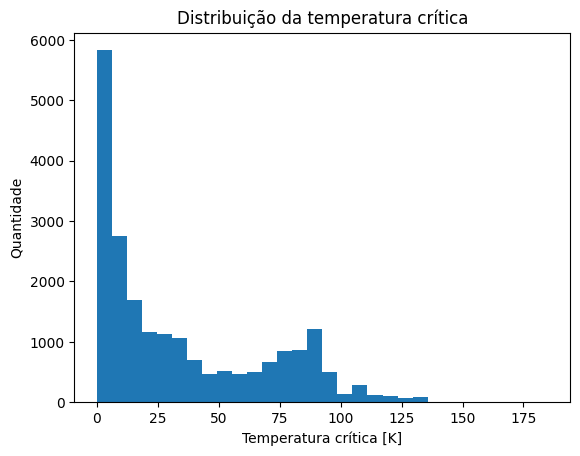

In [69]:
#Gráfico de distribuição da variável alvo: critical_temp
plt.hist(df["critical_temp"], bins=30)
plt.xlabel("Temperatura crítica [K]")
plt.ylabel("Quantidade")
plt.title("Distribuição da temperatura crítica")
plt.show()

In [70]:
df.to_csv("superconductivity_duplicated.csv", index=False)